# Tarea 1 – Analítica de Datos (MACI 2026)

**Alumno:** Keyden Urbina

**Mercado de celulares en Chile (solotodo.cl) y modelo de rango de precios**

Las cifras de las interpretaciones corresponden a la extracción del **27-10-2026**. Si vuelves a correr el scraping, los precios cambian: revisa los números antes de entregar.

## Objetivo 2 · Modelo de clasificación de rango de precio

### 2.1 Variable objetivo `rango_precio`

**Decisión clave:** se trabaja con **una fila por modelo nuevo** (precio = mediana de sus tiendas). Si se usara una fila por tienda, el mismo celular (mismas características) podría quedar en train y en test, y el modelo "se sabría la respuesta".

**Variables:** solo las características técnicas limpias. La **marca se excluye a propósito**: los equipos de la emprendedora no tienen historia de marca, así que el modelo debe estimar el precio por lo que el teléfono *trae*, no por el logo.

In [8]:
# Librerías que usa este notebook
import numpy as np                     # np.inf para el último tramo de precio
import pandas as pd                    # tablas
import matplotlib.pyplot as plt        # matriz de confusión e importancia de variables
from pathlib import Path               # rutas de carpetas

# Ruta a data/processed: la busca subiendo desde donde se ejecuta (sirve desde notebooks/ o desde la raíz)
PROC = next(p / "data" / "processed" for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data" / "processed").is_dir())
print("Datos desde:", PROC / "data_processed.csv")

Datos desde: /Users/keydenurbina/Desktop/github/Proyecto Web Scraping/data/processed/data_processed.csv


In [9]:
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

d = pd.read_csv(PROC / "data_processed.csv")
X_cols = ["memoria_gb", "ram_gb", "pantalla_pulg", "camara_principal_mp", "camara_frontal_mp", "bateria_mah", "peso_g", "nfc"]

# 1 fila por modelo nuevo (precio = mediana entre tiendas). Si no, el mismo celular caería en train y test → trampa.
m = d[d.reacondicionado == 0].groupby("nombre").agg({**{c: "first" for c in X_cols}, "precio_oferta": "median"})
etiquetas = ["Muy bajo", "Bajo", "Medio", "Alto", "Muy alto"]
m["rango_precio"] = pd.cut(m.precio_oferta, [0, 100_000, 200_000, 320_000, 570_000, np.inf], labels=False, right=False)  # [a, b)
m.rango_precio.value_counts().sort_index().rename(index=dict(enumerate(etiquetas)))

rango_precio
Muy bajo     8
Bajo        46
Medio       49
Alto        39
Muy alto    59
Name: count, dtype: int64

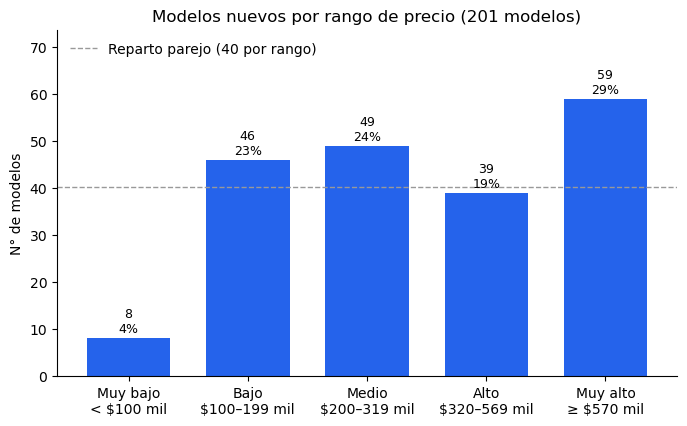

rango_precio
Muy bajo     8
Bajo        46
Medio       49
Alto        39
Muy alto    59
Name: count, dtype: int64

In [10]:
# Gráfico: cuántos modelos caen en cada rango de precio
conteo = m.rango_precio.value_counts().reindex(range(5), fill_value=0)     # n° de modelos por rango (0 a 4); si un rango queda vacío, pone 0
rangos = ["< $100 mil", "$100–199 mil", "$200–319 mil", "$320–569 mil", "≥ $570 mil"]
ax = conteo.plot.bar(figsize=(8, 4.5), color="#2563eb", width=0.7, rot=0)
ax.set_xticks(range(5), [f"{e}\n{r}" for e, r in zip(etiquetas, rangos)])  # etiqueta + rango de precio bajo cada barra
ax.bar_label(ax.containers[0], labels=[f"{v}\n{v/len(m):.0%}" for v in conteo], padding=2, fontsize=9)   # n° y % sobre cada barra
ax.axhline(len(m) / 5, color="#999", linestyle="--", linewidth=1,          # línea de referencia: si los 5 rangos fueran iguales
           label=f"Reparto parejo ({len(m) / 5:.0f} por rango)")
ax.legend(handles=ax.lines, loc="upper left", frameon=False)               # la leyenda solo explica la línea
ax.set_ylim(top=conteo.max() * 1.25)                                       # espacio para las etiquetas
ax.set(title=f"Modelos nuevos por rango de precio ({len(m)} modelos)", xlabel="", ylabel="N° de modelos")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

conteo.rename(index=dict(enumerate(etiquetas)))                            # la tabla se muestra debajo del gráfico

- **“Muy bajo” es el problema:** solo 8 modelos, 5 veces menos que un reparto parejo. Al separar el 20% para prueba quedan ~2 en el test, así que la métrica de esa clase será muy inestable: un solo acierto o error la mueve un 50%.

- **“Muy alto”** es la clase más grande (29%), porque abarca todo lo que cuesta desde $570 mil, sin límite superior.

**Este desbalance justifica tres decisiones del modelo:** 
1. Dividir los datos estratificado (stratify).
2. Dar más peso a las clases chicas (class_weight="balanced").
3. Elegir el modelo con el F1 macro, que pondera igual cada rango.

### 2.2 División train / validación / test

In [11]:
X, y = m[X_cols], m.rango_precio
# 80% / 20% test → y del 80%, otro 80% / 20% para train / validación. stratify mantiene la proporción de cada rango.
X_80, X_te, y_80, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X_80, y_80, test_size=0.2, stratify=y_80, random_state=42)
print("train", len(X_tr), "| val", len(X_val), "| test", len(X_te))

train 128 | val 32 | test 41


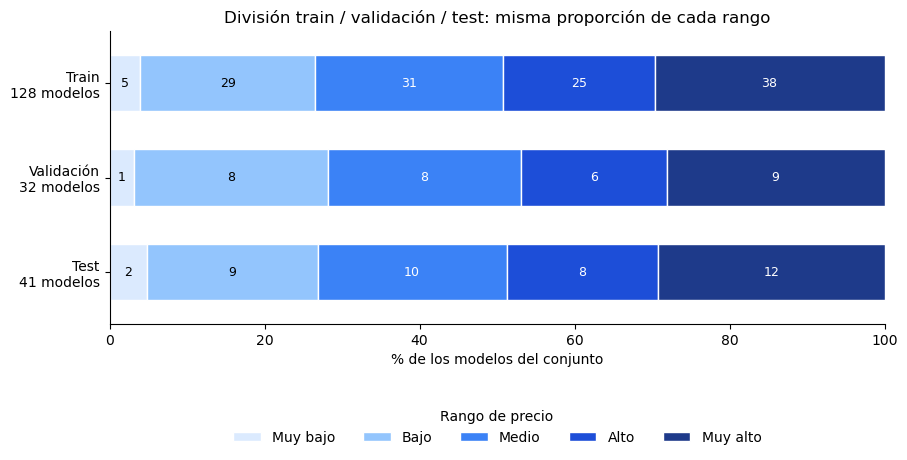

,Train,Validación,Test
Muy bajo,5,1,2
Bajo,29,8,9
Medio,31,8,10
Alto,25,6,8
Muy alto,38,9,12


In [12]:
# Gráfico: composición de cada conjunto por rango de precio (comprueba que stratify mantuvo las proporciones)
reparto = pd.DataFrame({"Train": y_tr.value_counts(), "Validación": y_val.value_counts(), "Test": y_te.value_counts()}
                       ).reindex(range(5), fill_value=0).set_axis(etiquetas)   # filas: rangos; columnas: conjuntos (n° de modelos)
pct = reparto / reparto.sum() * 100                                       # % dentro de cada conjunto (cada columna suma 100)
ax = pct.T.plot.barh(stacked=True, figsize=(10, 3.8), width=0.6, edgecolor="white",
                     color=["#dbeafe", "#93c5fd", "#3b82f6", "#1d4ed8", "#1e3a8a"])   # azul claro → oscuro = precio bajo → alto
for cont, rango, tinta in zip(ax.containers, etiquetas, ["black", "black", "white", "white", "white"]):
    ax.bar_label(cont, labels=[n if n else "" for n in reparto.loc[rango]], label_type="center", fontsize=9, color=tinta)   # n° de modelos
ax.set_yticks(range(3), [f"{s}\n{n} modelos" for s, n in reparto.sum().items()])   # nombre del conjunto + su tamaño
ax.invert_yaxis()                                                         # Train arriba
ax.set(title="División train / validación / test: misma proporción de cada rango", xlabel="% de los modelos del conjunto", xlim=(0, 100))
ax.legend(title="Rango de precio", loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=5, frameon=False)   # leyenda bajo el gráfico
ax.spines[["top", "right"]].set_visible(False)
plt.show()

reparto                                                                   # la tabla se muestra debajo del gráfico